# 25. Bộ hình chính của phần so sánh cấu hình

Hình của mười sổ tay tuần 3 hiện nằm rải trong mười thư mục, vể ở mười thời điểm khác nhau, và không thống nhất về cách đặt nhãn hay cách gọi tên hai neo. Một báo cáo học thuật không thể nhận những hình đó nguyên trạng.

Sổ tay này vẽ lại bốn hình còn thiếu từ đúng tệp hợp nhất, theo một quy ước duy nhất: màu xanh cho neo quan sát thật, màu cam cho neo bước cuối, vạch nét đứt đen cho mốc giữ nguyên dự báo cuối, mọi trục đặt tên bằng tiếng Việt có dấu. Sáu hình của báo cáo do ba sổ tay đợt hợp nhất sinh ra, đều vào cùng một thư mục.

Không huấn luyện mô hình. Chi phí dưới hai phút.

> **Vị trí trong chuỗi tái lập:** notebook 25 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 09-Ba_ham_mat_mat_hai_neo, 10-Luoi_nam_hat_giong, 11-Chi_so_theo_nhom_kenh, 12-Phan_tang_theo_do_tre, 13-Moc_trung_binh_dich_chuyen, 14-Doi_chung_moc_manh_nhat, 15-Neo_B_ham_tuyet_doi_nam_hat_giong, 16-Kiem_tra_thang_do_kenh, 17-Neo_theo_nguong_do_phu, 18-Phan_tang_gop_tang_cuoi, 22-Hop_nhat_chi_so, 23-Kiem_dinh_dong_nhat, 24-Bang_kenh_va_phan_tang.
>
> **Thư mục kết quả:** `Output/processed/w3_artefacts_tong_hop/`.
>
> **Mã định danh nội bộ:** `W3.W4_29`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_artefacts_tong_hop"  #@param {type:"string"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:56:23
run_tag      w3_artefacts_tong_hop
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


In [4]:
# Đợt hợp nhất dùng thêm hai thư mục con để tách bảng và gói nộp.
OUT_PROC = OUT / "processed"
BANG = RUN_DIR / "bang"
GOI = RUN_DIR / "goi"
for d in (BANG, GOI):
    d.mkdir(parents=True, exist_ok=True)


def ghi_bang(ten, cot, hang):
    """Ghi một bảng ra tệp CSV, dùng bảng mã có dấu hiệu thứ tự byte cho Excel."""
    import csv
    duong = BANG / ten
    with open(duong, "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(cot)
        for r in hang:
            w.writerow([r.get(k, "") for k in cot])
    print("Đã ghi bảng", ten, "|", len(hang), "dòng |",
          duong.stat().st_size, "byte")
    return duong


def ghi_json(ten, doi_tuong):
    """Ghi một tệp tổng hợp, luôn giữ nguyên dấu tiếng Việt."""
    duong = RUN_DIR / ten
    duong.write_text(json.dumps(doi_tuong, ensure_ascii=False, indent=1),
                     encoding="utf-8")
    print("Đã ghi tệp", ten, "|", duong.stat().st_size, "byte")
    return duong


print("Thư mục bảng:", BANG)
print("Thư mục gói :", GOI)


Thư mục bảng: /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/bang
Thư mục gói : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/goi


In [5]:
# Danh mục mười lần chạy của tuần 3, khai báo tường minh theo ba thành phần:
# Mã sổ tay, tên thư mục con và tên tệp tổng hợp mà sổ tay đó đã ghi ra.
DANH_MUC_W3 = [
    ("W3_16", "w3_16_ba_ham_mat_mat_hai_neo", "W3_ba_ham_mat_mat_hai_neo.json"),
    ("W3_17", "w3_17_luoi_nam_hat_giong", "W3_luoi_nam_hat_giong.json"),
    ("W3_18", "w3_18_chi_so_theo_nhom_kenh", "W3_chi_so_theo_nhom_kenh.json"),
    ("W3_19", "w3_19_phan_tang_theo_do_tre", "W3_phan_tang_theo_do_tre.json"),
    ("W3_20", "w3_20_moc_trung_binh_dich_chuyen",
     "W3_moc_trung_binh_dich_chuyen.json"),
    ("W3_21", "w3_21_doi_chung_moc_manh_nhat", "W3_doi_chung_moc_manh_nhat.json"),
    ("W3_22", "w3_22_neo_b_ham_tuyet_doi_nam_hat_giong",
     "W3_neo_b_mae_nam_hat_giong.json"),
    ("W3_23", "w3_23_kiem_tra_thang_do_kenh", "W3_kiem_tra_thang_do_kenh.json"),
    ("W3_24", "w3_24_neo_theo_nguong_do_phu", "W3_neo_theo_nguong_do_phu.json"),
    ("W3_25", "w3_25_phan_tang_gop_tang_cuoi",
     "W3_phan_tang_gop_tang_cuoi.json"),
]


def doc_tong_hop(ma):
    """Đọc tệp tổng hợp của một sổ tay tuần 3 theo mã sổ tay."""
    for m, thu_muc, ten_tep in DANH_MUC_W3:
        if m == ma:
            duong = OUT / "processed" / thu_muc / ten_tep
            assert duong.exists(), "Không thấy " + str(duong)
            return json.loads(duong.read_text())
    raise KeyError("Không có mã sổ tay " + str(ma))


CO_MAT, THIEU = [], []
for ma, thu_muc, ten_tep in DANH_MUC_W3:
    duong = OUT / "processed" / thu_muc / ten_tep
    (CO_MAT if duong.exists() else THIEU).append(ma)
print("Lần chạy đã có tệp tổng hợp:", ", ".join(CO_MAT))
print("Lần chạy còn thiếu        :", ", ".join(THIEU) if THIEU else "không có")
assert not THIEU, ("Còn thiếu tệp tổng hợp của " + ", ".join(THIEU) +
                   ". Hãy chạy lại các sổ tay đó trước khi hợp nhất.")


Lần chạy đã có tệp tổng hợp: W3_16, W3_17, W3_18, W3_19, W3_20, W3_21, W3_22, W3_23, W3_24, W3_25
Lần chạy còn thiếu        : không có


In [6]:
# Mọi sổ tay từ đây trở đi đọc tệp hợp nhất chứ không tự quét thư mục.
TEP_HOP_NHAT = RUN_DIR / "W3_HOP_NHAT_CHI_SO.json"
assert TEP_HOP_NHAT.exists(), (
    "Không thấy " + str(TEP_HOP_NHAT) + ". Hãy chạy notebook 22 và notebook 23 trước.")
HOP_NHAT = json.loads(TEP_HOP_NHAT.read_text())
# Chỉ nhận tệp hợp nhất có phạm vi quét khoá ở tuần 3.
assert HOP_NHAT.get("phien_ban_hop_nhat") == "W3.W4_26", (
    "Tệp hợp nhất chưa được sinh từ notebook 22. Hãy chạy notebook 22 trước.")
print("Phạm vi quét của tệp hợp nhất: tới tuần", HOP_NHAT.get("pham_vi_tuan_toi_da"))
GOC = HOP_NHAT["tong_hop_goc"]
MSE_MOC = HOP_NHAT["mse_persistence"]
MAE_MOC = HOP_NHAT["mae_persistence"]
print("Đã đọc tệp hợp nhất, gồm", len(GOC), "lần chạy gốc của tuần 3")
print("Số cấu hình đã hợp nhất  :", HOP_NHAT["so_cau_hinh"])
print("Số phép kiểm định đã có:",
      HOP_NHAT.get("kiem_dinh", {}).get("so_phep", 0))


Phạm vi quét của tệp hợp nhất: tới tuần 3
Đã đọc tệp hợp nhất, gồm 13 lần chạy gốc của tuần 3
Số cấu hình đã hợp nhất  : 18
Số phép kiểm định đã có: 13


## 2. Hình năm: họ mốc mạnh dần và vị trí của hai neo

Một mô hình thắng mốc giữ nguyên dự báo cuối chưa phải là kết quả đáng tin, vì mốc đó rất yếu. Bảy mốc trung bình dịch chuyển của notebook 13 mạnh hơn hẳn, và notebook 14 đã đối chứng trực tiếp với mốc mạnh nhất trong họ đó. Hình này sắp xếp toàn bộ họ mốc cùng hai neo lên một trục duy nhất, nên người đọc tự đánh giá được luận điểm mạnh đến đâu mà không phải tin vào lời dẫn.

Số mốc trong họ trung bình dịch chuyển: 7
Mốc mạnh nhất theo sai số bình phương: giam_K5
Mốc mạnh nhất theo sai số tuyệt đối : giam_K5
Kết luận của notebook 14: Mô hình tuyến tính thắng mốc mạnh nhất trên cả hai chỉ tiêu
Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/figures/W3_T05_ho_moc_va_hai_neo.png


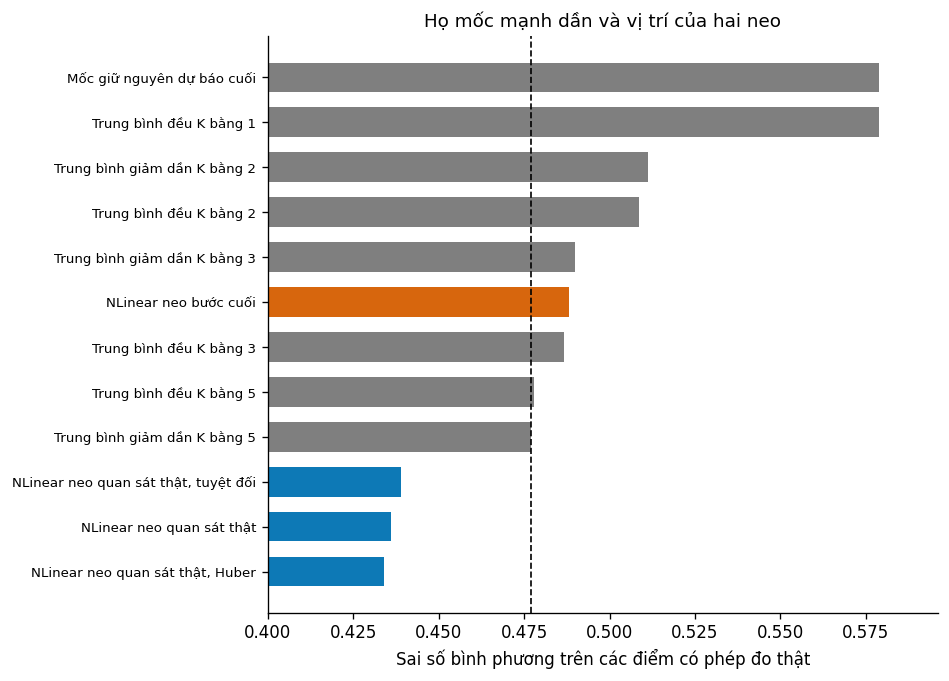

In [7]:
d20 = GOC["W3_20"]
d21 = GOC["W3_21"]
CHI_SO_MOC = d21.get("chi_so_moc", {})
MOC_HO = []
for ten in sorted(CHI_SO_MOC):
    MOC_HO.append({"ten": ten,
                   "mse": float(CHI_SO_MOC[ten]["mse"]),
                   "mae": float(CHI_SO_MOC[ten]["mae"])})
print("Số mốc trong họ trung bình dịch chuyển:", len(MOC_HO))
print("Mốc mạnh nhất theo sai số bình phương:", d21["moc_manh_nhat_mse"])
print("Mốc mạnh nhất theo sai số tuyệt đối :", d21["moc_manh_nhat_mae"])
print("Kết luận của notebook 14:", d21["ket_luan"])

def chi_so_cau_hinh(khoa, truong):
    for r in HOP_NHAT["cau_hinh"]:
        if r["khoa_cau_hinh"] == khoa:
            return float(r[truong])
    return None


DIEM = [("Mốc giữ nguyên dự báo cuối", MSE_MOC, MAE_MOC, "moc")]
for r in MOC_HO:
    nhan = r["ten"].replace("deu_K", "Trung bình đều K bằng ").replace(
        "giam_K", "Trung bình giảm dần K bằng ")
    DIEM.append((nhan, r["mse"], r["mae"], "moc"))
for khoa, nhan, nhom in (("nlinear|A|mse", "NLinear neo bước cuối", "A"),
                         ("nlinear|B|mse", "NLinear neo quan sát thật", "B"),
                         ("nlinear|B|huber", "NLinear neo quan sát thật, Huber", "B"),
                         ("nlinear|B|mae", "NLinear neo quan sát thật, tuyệt đối", "B")):
    mse = chi_so_cau_hinh(khoa, "mse_trung_binh")
    mae = chi_so_cau_hinh(khoa, "mae_trung_binh")
    if mse is not None:
        DIEM.append((nhan, mse, mae, nhom))
DIEM.sort(key=lambda t: -t[1])

mau_nhom = {"moc": PALETTE[6], "A": PALETTE[1], "B": PALETTE[0]}
fig, ax = plt.subplots(figsize=(7.8, 0.33 * len(DIEM) + 1.6))
y = np.arange(len(DIEM))
for i, t in enumerate(DIEM):
    ax.barh([i], [t[1]], height=0.66, color=mau_nhom[t[3]],
            alpha=0.5 if t[3] == "moc" else 0.95)
ax.axvline(min(t[1] for t in DIEM if t[3] == "moc"), color=PALETTE[6],
           ls="--", lw=1.0)
ax.set_yticks(y)
ax.set_yticklabels([t[0] for t in DIEM], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Sai số bình phương trên các điểm có phép đo thật")
ax.set_title("Họ mốc mạnh dần và vị trí của hai neo")
ax.set_xlim(0.40, max(t[1] for t in DIEM) * 1.03)
luu_hinh(fig, "W3_T05_ho_moc_va_hai_neo.png")
plt.show()


## 3. Hình sáu: ổn định theo hạt giống và kết quả âm tính của luật chọn neo

Hai nội dung này đặt cạnh nhau vì cùng phục vụ một mục đích: chứng minh kết luận chính không phụ thuộc may mắn. Bên trái là phân bố theo hạt giống của các cấu hình có đủ năm điểm. Bên phải là kết quả âm tính của luật chọn neo theo độ phủ, được giữ lại trong báo cáo đúng vì nó âm tính.

Công bố kết quả âm tính là lựa chọn có chủ đích. Nó chặn trước một câu hỏi phản biện dễ đoán, là vì sao không chọn neo riêng cho từng kênh, và cho câu trả lời bằng số liệu thay vì bằng phỏng đoán.

Cấu hình có đủ năm hạt giống: nlinear|B|huber, dlinear|B|huber, nlinear|trung|mse, dlinear|B|mse, nlinear|B|mse, nlinear|B|mae, nlinear|D|mse, nlinear|C|mse, nlinear|A|huber, nlinear|A|mse, nlinear|A|mae
Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/figures/W3_T06_on_dinh_va_ket_qua_am_tinh.png


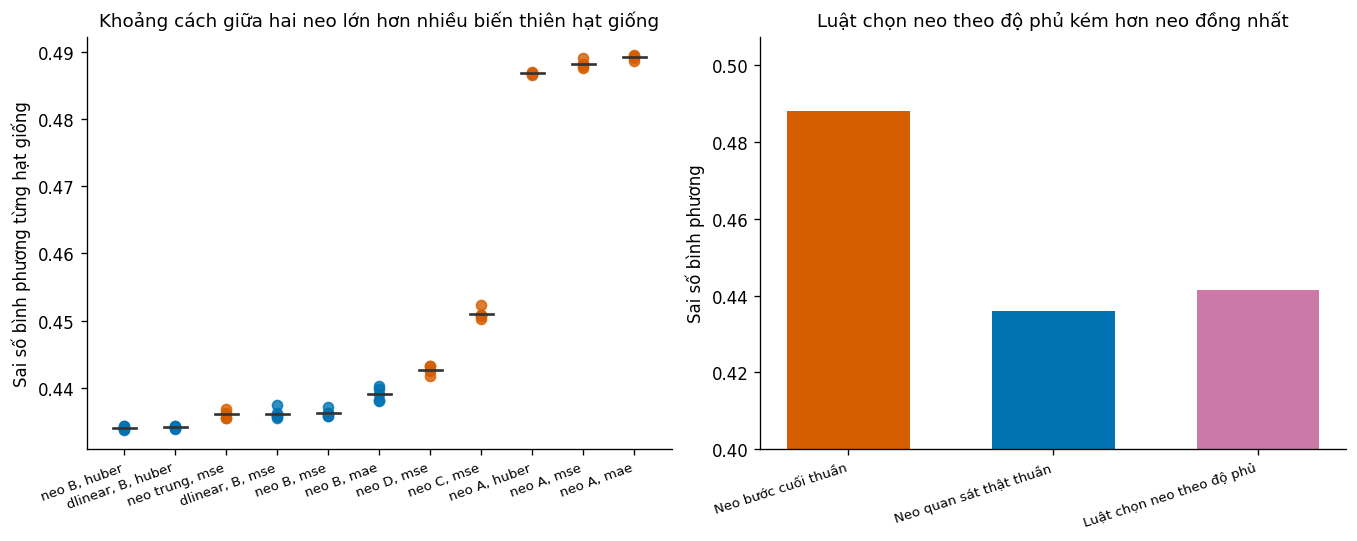

Số kênh được giữ neo quan sát thật: 31
Số kênh bị chuyển về neo bước cuối: 6
Danh sách: DiasABP, HR, MAP, SysABP, Urine, Weight
Kết luận của notebook 17: Luật chọn neo theo kênh kém hơn neo B thuần


In [8]:
fig, truc = plt.subplots(1, 2, figsize=(11.2, 4.4))
d22 = GOC["W3_22"]
d17 = GOC["W3_17"]
NHOM_HAT = []
for r in HOP_NHAT["cau_hinh"]:
    if r["so_hat_giong"] < 5:
        continue
    NHOM_HAT.append(r["khoa_cau_hinh"])
print("Cấu hình có đủ năm hạt giống:", ", ".join(NHOM_HAT))
DU_LIEU_HAT = []
for khoa in NHOM_HAT:
    # Chỉ lấy bản được dùng, để mỗi hạt giống hiện đúng một điểm.
    gia_tri = [r["mse"] for r in HOP_NHAT["tung_lan"]
               if r["khoa_cau_hinh"] == khoa and r.get("duoc_dung", True)]
    DU_LIEU_HAT.append((khoa, sorted(gia_tri)))
for i, (khoa, gia_tri) in enumerate(DU_LIEU_HAT):
    mau = PALETTE[0] if "|B|" in khoa else PALETTE[1]
    truc[0].plot([i] * len(gia_tri), gia_tri, "o", color=mau, ms=6, alpha=0.8)
    truc[0].plot([i - 0.22, i + 0.22], [np.mean(gia_tri)] * 2,
                 color="#333333", lw=1.6)
truc[0].set_xticks(np.arange(len(DU_LIEU_HAT)))
truc[0].set_xticklabels([k.replace("nlinear|", "neo ").replace("|", ", ")
                         for k, _ in DU_LIEU_HAT], rotation=20, ha="right",
                        fontsize=8)
truc[0].set_ylabel("Sai số bình phương từng hạt giống")
truc[0].set_title("Khoảng cách giữa hai neo lớn hơn nhiều biến thiên hạt giống")

d24 = GOC["W3_24"]
thuan = d24.get("chi_so_neo_thuan", {})
nhan24, gia_tri24, mau24 = [], [], []
for khoa, nhan, mau in (("A", "Neo bước cuối thuần", PALETTE[1]),
                        ("B", "Neo quan sát thật thuần", PALETTE[0])):
    if khoa in thuan:
        v = thuan[khoa]
        nhan24.append(nhan)
        gia_tri24.append(float(v["mse"] if isinstance(v, dict) else v))
        mau24.append(mau)
nhan24.append("Luật chọn neo theo độ phủ")
gia_tri24.append(float(d24["mse_neo_lai"]))
mau24.append(PALETTE[3])
truc[1].bar(np.arange(len(nhan24)), gia_tri24, color=mau24, width=0.6)
truc[1].set_xticks(np.arange(len(nhan24)))
truc[1].set_xticklabels(nhan24, rotation=18, ha="right", fontsize=8)
truc[1].set_ylabel("Sai số bình phương")
truc[1].set_ylim(0.40, max(gia_tri24) * 1.04)
truc[1].set_title("Luật chọn neo theo độ phủ kém hơn neo đồng nhất")
luu_hinh(fig, "W3_T06_on_dinh_va_ket_qua_am_tinh.png")
plt.show()
print("Số kênh được giữ neo quan sát thật:", d24["so_kenh_dung_neo_b"])
print("Số kênh bị chuyển về neo bước cuối:", len(d24["kenh_dung_neo_a"]))
print("Danh sách:", ", ".join(d24["kenh_dung_neo_a"]))
print("Kết luận của notebook 17:", d24["ket_luan"])


## 4. Đối chiếu sáu kênh bị chuyển neo với sáu kênh neo thật sự làm xấu

Đây là phần giải thích nguyên nhân của kết quả âm tính, và là phần có giá trị khoa học cao nhất trong cả notebook 17. Nếu luật chọn neo đúng thì tập kênh bị chuyển về neo bước cuối phải trùng với tập kênh mà neo quan sát thật thực sự làm xấu. Ô này tính độ trùng đó bằng số liệu và chỉ ra chính xác mất mát đã xảy ra ở đâu.

In [9]:
bang_kenh = {r["kenh"]: r for r in HOP_NHAT["truc_giai_thich"]["bang_kenh"]}
bi_chuyen = list(d24["kenh_dung_neo_a"])
lam_xau = sorted([r["kenh"] for r in bang_kenh.values()
                  if r["hieu_ung_mse"] is not None and float(r["hieu_ung_mse"]) > 0],
                 key=lambda k: -float(bang_kenh[k]["hieu_ung_mse"]))
trung = sorted(set(bi_chuyen) & set(lam_xau))
print("Kênh bị chuyển về neo bước cuối theo luật độ phủ:")
for k in bi_chuyen:
    r = bang_kenh[k]
    print("   ", k.ljust(14), "độ phủ",
          str(round(100.0 * float(r["do_phu"]), 2)).rjust(6),
          "| hiệu ứng của neo", round(float(r["hieu_ung_mse"]), 6),
          "->", "neo làm xấu" if float(r["hieu_ung_mse"]) > 0 else "neo làm tốt")
print("")
print("Kênh mà neo quan sát thật thực sự làm xấu:")
for k in lam_xau:
    r = bang_kenh[k]
    print("   ", k.ljust(14), "độ phủ",
          str(round(100.0 * float(r["do_phu"]), 2)).rjust(6),
          "| hiệu ứng", round(float(r["hieu_ung_mse"]), 6),
          "| bị luật chuyển neo", k in bi_chuyen)
print("")
print("Số kênh trùng giữa hai tập:", len(trung), "trên", len(bi_chuyen),
      "kênh bị chuyển")
print("Danh sách trùng:", ", ".join(trung) if trung else "không có")
mat_mat = sum(-float(bang_kenh[k]["hieu_ung_mse"]) for k in bi_chuyen
              if float(bang_kenh[k]["hieu_ung_mse"]) < 0)
print("Tổng lợi ích bị trả lại do chuyển sai kênh:", round(mat_mat, 6))
print("Kết luận: độ phủ dự báo đúng độ lớn của hiệu ứng nhưng không dự báo đúng")
print("dấu, nên không dùng được làm tiêu chí chọn neo.")
HOP_NHAT["doi_chieu_neo_lai"] = {
    "kenh_bi_chuyen": bi_chuyen,
    "kenh_neo_lam_xau": lam_xau,
    "kenh_trung": trung,
    "loi_ich_bi_tra_lai": float(mat_mat),
}
ghi_json("W3_HOP_NHAT_CHI_SO.json", HOP_NHAT)


Kênh bị chuyển về neo bước cuối theo luật độ phủ:
    DiasABP        độ phủ  55.76 | hiệu ứng của neo -0.007313 -> neo làm tốt
    HR             độ phủ   91.4 | hiệu ứng của neo -0.013097 -> neo làm tốt
    MAP            độ phủ  55.53 | hiệu ứng của neo 0.000282 -> neo làm xấu
    SysABP         độ phủ  55.77 | hiệu ứng của neo -0.006461 -> neo làm tốt
    Urine          độ phủ  70.74 | hiệu ứng của neo -0.013126 -> neo làm tốt
    Weight         độ phủ  51.56 | hiệu ứng của neo -0.038927 -> neo làm tốt

Kênh mà neo quan sát thật thực sự làm xấu:
    NIMAP          độ phủ  42.21 | hiệu ứng 0.015118 | bị luật chuyển neo False
    NIDiasABP      độ phủ  42.72 | hiệu ứng 0.009462 | bị luật chuyển neo False
    NISysABP       độ phủ  42.79 | hiệu ứng 0.008249 | bị luật chuyển neo False
    Cholesterol    độ phủ   0.21 | hiệu ứng 0.00807 | bị luật chuyển neo False
    RespRate       độ phủ  24.79 | hiệu ứng 0.007807 | bị luật chuyển neo False
    MAP            độ phủ  55.53 | hiệu ứng 0.

PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/W3_HOP_NHAT_CHI_SO.json')

## 5. Danh mục hình đã có

Sáu hình được đánh số từ một đến sáu theo đúng thứ tự sẽ xuất hiện trong báo cáo. Quy ước đặt tên gắn số thứ tự vào tên tệp, nên khi chèn vào bản soạn thảo không còn khâu đoán xem hình nào ứng với mục nào.

In [10]:
MO_TA_HINH = {
    "W3_T01_thu_hang_cau_hinh.png":
        "Thứ hạng mọi cấu hình trên cùng mốc Persistence",
    "W3_T02_khoang_tin_cay_hop_nhat.png":
        "Khoảng tin cậy của mọi phép so sánh, tính lại đồng nhất",
    "W3_T03_hieu_ung_theo_kenh.png":
        "Lợi ích của neo theo độ phủ của từng kênh",
    "W3_T04_phan_tang_do_tre.png":
        "Hiệu ứng và đóng góp theo tầng độ trễ",
    "W3_T05_ho_moc_va_hai_neo.png":
        "Họ mốc mạnh dần và vị trí của hai neo",
    "W3_T06_on_dinh_va_ket_qua_am_tinh.png":
        "Ổn định theo hạt giống và kết quả âm tính của luật chọn neo",
}
thieu = []
for ten, mo_ta in MO_TA_HINH.items():
    p = FIGS / ten
    if p.exists():
        print("có   ", ten.ljust(44), p.stat().st_size, "byte |", mo_ta)
    else:
        thieu.append(ten)
        print("thiếu", ten.ljust(44), "|", mo_ta)
print("")
print("Số hình đủ:", len(MO_TA_HINH) - len(thieu), "trên", len(MO_TA_HINH))
if thieu:
    print("Hãy chạy lại sổ tay sinh ra các hình còn thiếu trước khi sang notebook 26.")
HOP_NHAT["danh_muc_hinh"] = MO_TA_HINH
ghi_json("W3_HOP_NHAT_CHI_SO.json", HOP_NHAT)


có    W3_T01_thu_hang_cau_hinh.png                 253083 byte | Thứ hạng mọi cấu hình trên cùng mốc Persistence
có    W3_T02_khoang_tin_cay_hop_nhat.png           262186 byte | Khoảng tin cậy của mọi phép so sánh, tính lại đồng nhất
có    W3_T03_hieu_ung_theo_kenh.png                166317 byte | Lợi ích của neo theo độ phủ của từng kênh
có    W3_T04_phan_tang_do_tre.png                  167997 byte | Hiệu ứng và đóng góp theo tầng độ trễ
có    W3_T05_ho_moc_va_hai_neo.png                 173485 byte | Họ mốc mạnh dần và vị trí của hai neo
có    W3_T06_on_dinh_va_ket_qua_am_tinh.png        254399 byte | Ổn định theo hạt giống và kết quả âm tính của luật chọn neo

Số hình đủ: 6 trên 6
Đã ghi tệp W3_HOP_NHAT_CHI_SO.json | 225847 byte


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_artefacts_tong_hop/W3_HOP_NHAT_CHI_SO.json')